# Time Series Analysis and Forecasting of Monthly Airline Passengers (1949-1960)

**Subject:** Statistical Methods (SM) - Mini Project, TY BTech

This notebook/script performs a complete time series analysis on the classic
*Air Passengers* dataset (Box & Jenkins, 1976): exploration, decomposition,
stationarity testing, ACF/PACF based model identification, fitting of six
forecasting models, residual diagnostics, evaluation with MAE/RMSE/MAPE and a
24-month forecast with confidence intervals.

The same code is in `src/analysis.py` (plain script) and in
`time_series_analysis.ipynb` (executed notebook).

In [1]:
import itertools
import sys
import warnings
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:          # plain script -> no GUI needed
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)

# Project folders (works both as src/analysis.py and as the notebook in the root)
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
DATA = ROOT / "data" / "AirPassengers.csv"
FIG = ROOT / "outputs" / "figures"
OUT = ROOT / "outputs"
FIG.mkdir(parents=True, exist_ok=True)

# Consistent, colour-blind-checked palette and a clean light style
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110, "savefig.dpi": 130,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "axes.prop_cycle": matplotlib.cycler(color=C), "legend.frameon": False,
    "font.size": 10,
})


def save(fig, name):
    """Save a figure to outputs/figures and show it inline when inside Jupyter."""
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    if "ipykernel" in sys.modules:
        from IPython.display import display
        display(fig)
    plt.close(fig)
    print(f"[saved] outputs/figures/{name}.png")

## Step 1 - Load, clean and explore the data

The CSV has two columns: `Month` (YYYY-MM) and `Passengers` (thousands of
international airline passengers). We parse the month into a `DatetimeIndex`
with monthly-start frequency (`MS`), check for missing values / duplicates and
compute summary statistics.

In [2]:
df = pd.read_csv(DATA)
df["Month"] = pd.to_datetime(df["Month"], format="%Y-%m")
df = df.drop_duplicates("Month").set_index("Month").sort_index()
y = df["Passengers"].asfreq("MS").astype(float)
y.name = "Passengers"

print("Shape               :", df.shape)
print("Period              :", y.index.min().strftime("%b %Y"), "to", y.index.max().strftime("%b %Y"))
print("Missing values      :", int(y.isna().sum()))
print("Duplicate months    :", int(df.index.duplicated().sum()))
print("Frequency           :", y.index.freqstr)
print()
print(y.head())
print()
summary = y.describe().to_frame("Passengers ('000)")
summary.loc["skewness"] = stats.skew(y)
summary.loc["kurtosis"] = stats.kurtosis(y)
summary.loc["coef. of variation %"] = 100 * y.std() / y.mean()
print(summary.round(2))

Shape               : (144, 1)
Period              : Jan 1949 to Dec 1960
Missing values      : 0
Duplicate months    : 0
Frequency           : MS

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64

                      Passengers ('000)
count                            144.00
mean                             280.30
std                              119.97
min                              104.00
25%                              180.00
50%                              265.50
75%                              360.50
max                              622.00
skewness                           0.58
kurtosis                          -0.39
coef. of variation %              42.80


In [3]:
yearly = y.groupby(y.index.year).agg(["sum", "mean", "min", "max", "std"])
yearly["growth %"] = yearly["sum"].pct_change() * 100
print("Year-wise statistics:")
print(yearly.round(1))
summary.round(3).to_csv(OUT / "summary_statistics.csv")
yearly.round(2).to_csv(OUT / "yearly_statistics.csv")

Year-wise statistics:
          sum   mean    min    max   std  growth %
Month                                             
1949   1520.0  126.7  104.0  148.0  13.7       NaN
1950   1676.0  139.7  114.0  170.0  19.1      10.3
1951   2042.0  170.2  145.0  199.0  18.4      21.8
1952   2364.0  197.0  171.0  242.0  23.0      15.8
1953   2700.0  225.0  180.0  272.0  28.5      14.2
1954   2867.0  238.9  188.0  302.0  34.9       6.2
1955   3408.0  284.0  233.0  364.0  42.1      18.9
1956   3939.0  328.2  271.0  413.0  47.9      15.6
1957   4421.0  368.4  301.0  467.0  57.9      12.2
1958   4572.0  381.0  310.0  505.0  64.5       3.4
1959   5140.0  428.3  342.0  559.0  69.8      12.4
1960   5714.0  476.2  390.0  622.0  77.7      11.2


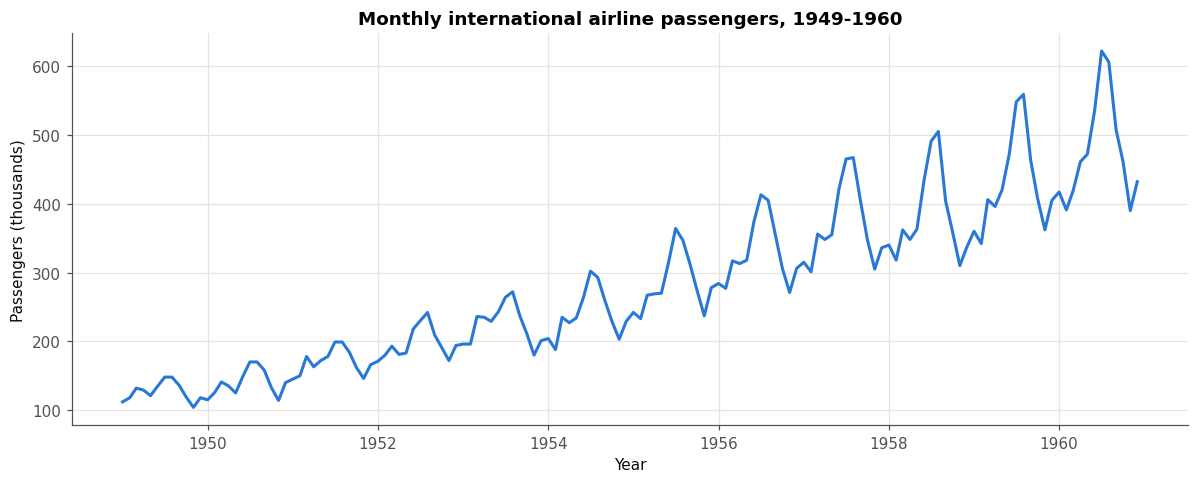

[saved] outputs/figures/01_time_series.png


In [4]:
fig, ax = plt.subplots()
ax.plot(y, color=C[0])
ax.set_title("Monthly international airline passengers, 1949-1960")
ax.set_ylabel("Passengers (thousands)")
ax.set_xlabel("Year")
save(fig, "01_time_series")

**Observation:** a clear upward **trend**, a repeating 12-month **seasonal**
pattern (peaks every July/August) and seasonal swings that get **larger as the
level rises** - a sign of *multiplicative* seasonality.

## Step 2 - Rolling statistics, decomposition and seasonality

A 12-month rolling mean smooths out seasonality and shows the trend; the rolling
standard deviation shows whether variance is constant.

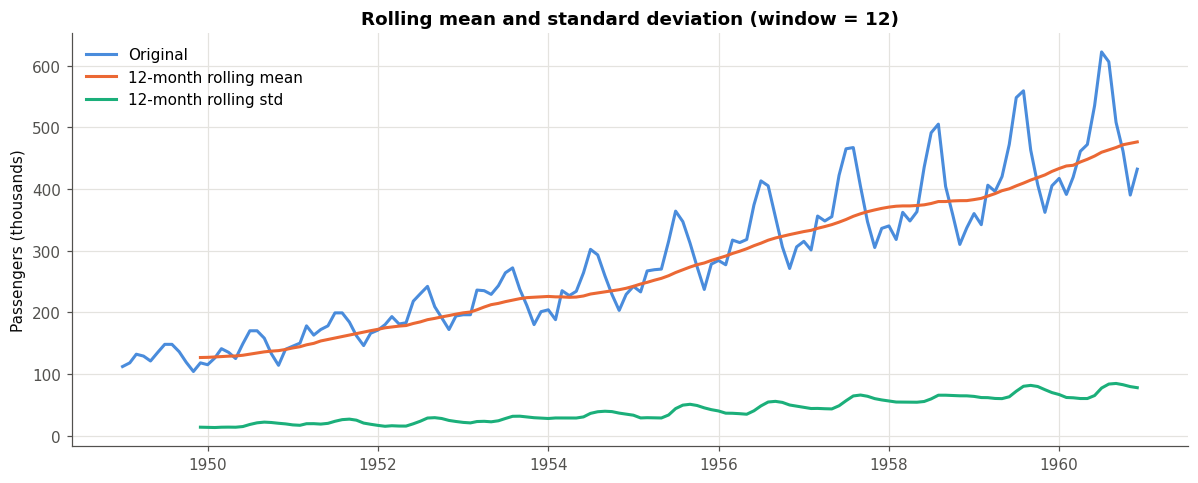

[saved] outputs/figures/02_rolling_statistics.png
Rolling std, first full window : 13.72
Rolling std, last window       : 77.74


In [5]:
roll_mean = y.rolling(12).mean()
roll_std = y.rolling(12).std()
fig, ax = plt.subplots()
ax.plot(y, color=C[0], label="Original", alpha=0.85)
ax.plot(roll_mean, color=C[1], label="12-month rolling mean")
ax.plot(roll_std, color=C[2], label="12-month rolling std")
ax.set_title("Rolling mean and standard deviation (window = 12)")
ax.set_ylabel("Passengers (thousands)")
ax.legend(loc="upper left")
save(fig, "02_rolling_statistics")
print("Rolling std, first full window :", round(roll_std.dropna().iloc[0], 2))
print("Rolling std, last window       :", round(roll_std.iloc[-1], 2))

Both mean and spread increase over time, so the series is **not stationary**.

### Classical decomposition
* **Additive:** $Y_t = T_t + S_t + R_t$ (constant seasonal amplitude)
* **Multiplicative:** $Y_t = T_t \times S_t \times R_t$ (seasonal amplitude grows with level)
* **STL** (Seasonal-Trend decomposition using LOESS) - robust, allows the seasonal
  pattern to change slowly; applied to log(Y) so that it is multiplicative on the original scale.

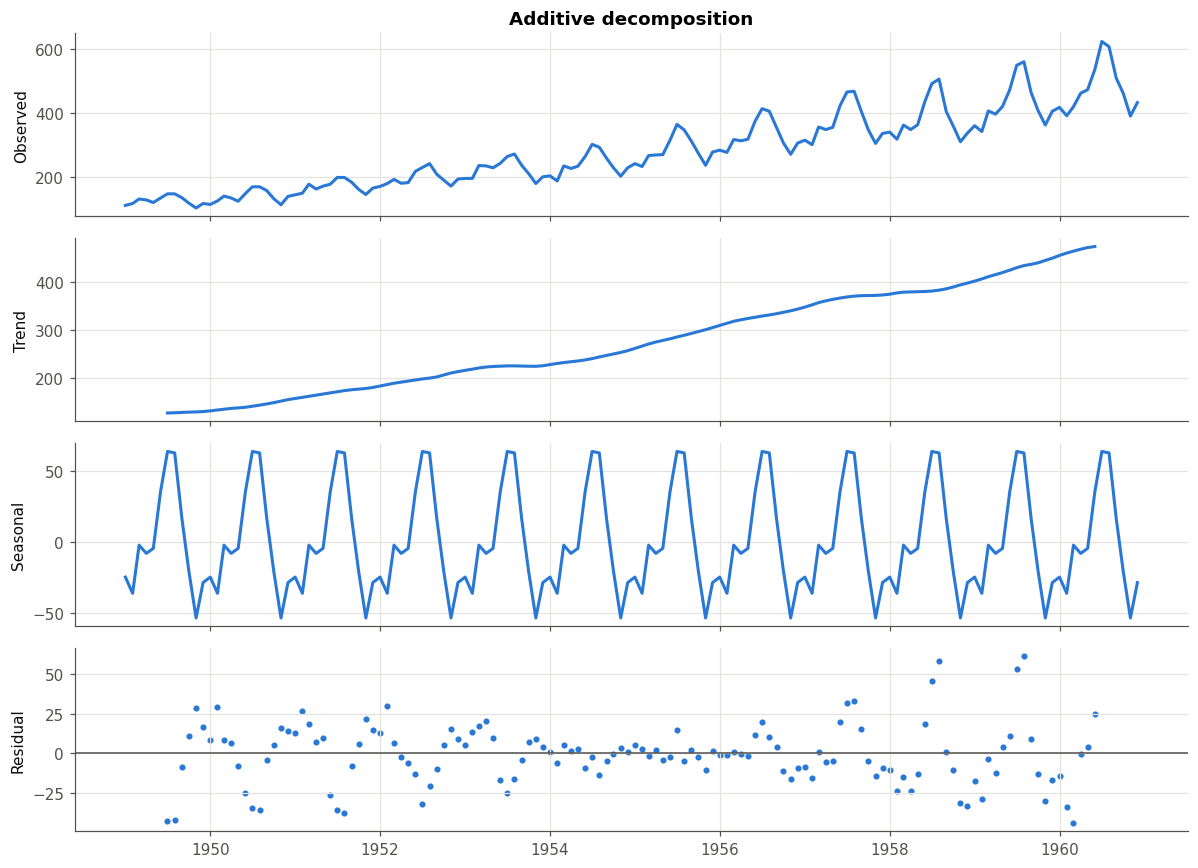

[saved] outputs/figures/03_decomposition_additive.png


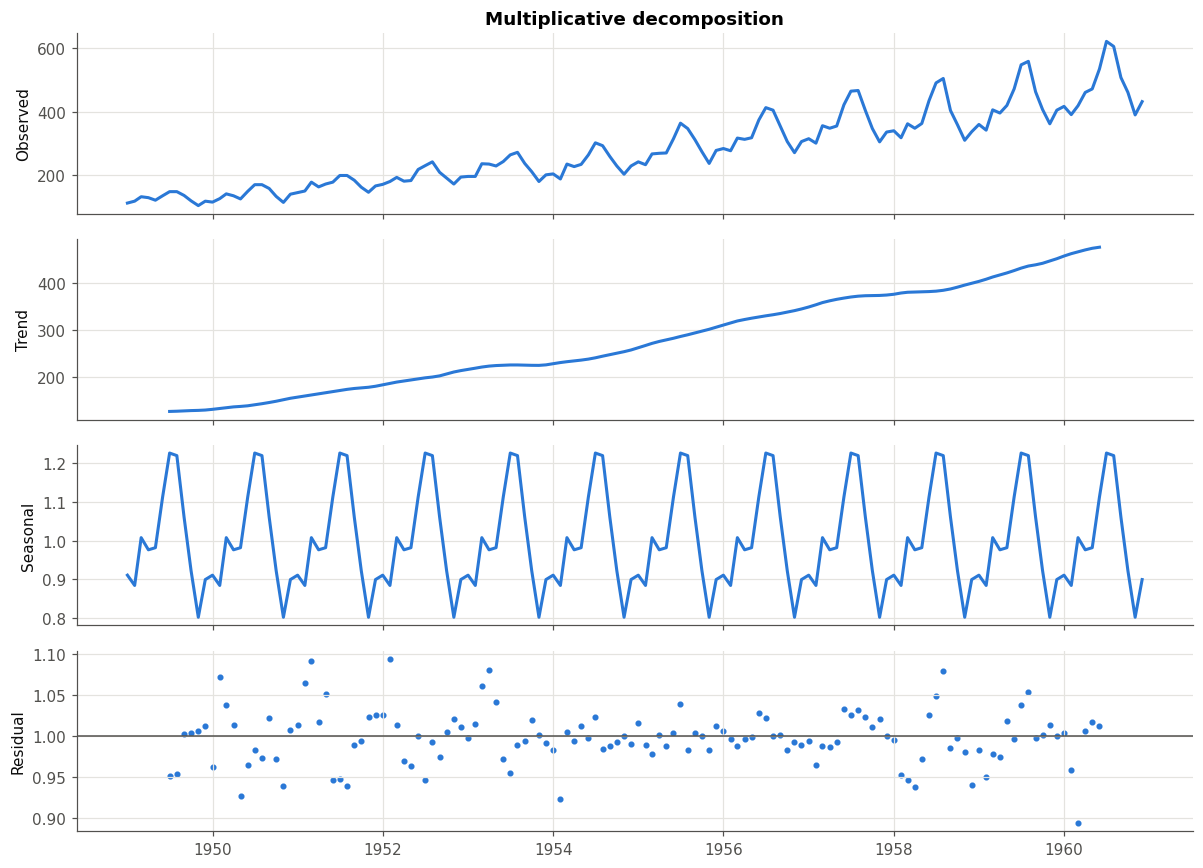

[saved] outputs/figures/04_decomposition_multiplicative.png


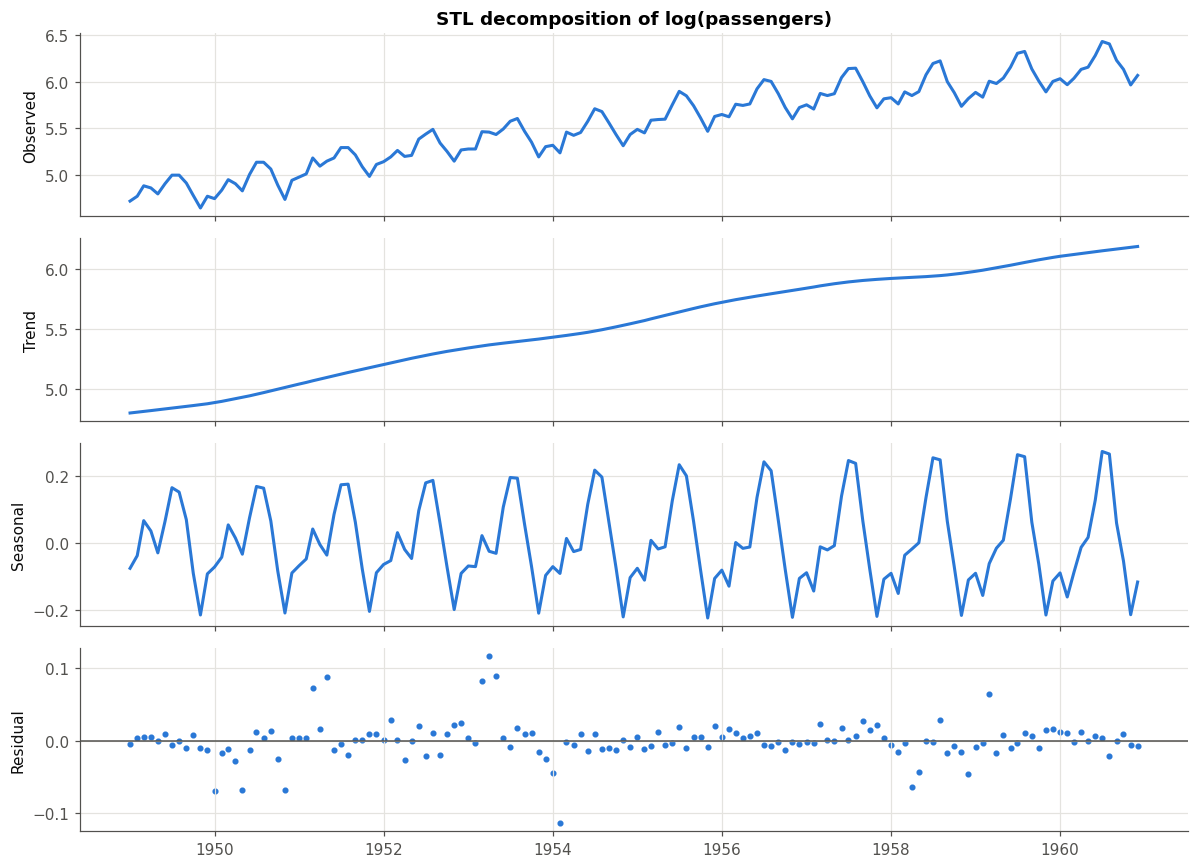

[saved] outputs/figures/05_decomposition_stl.png


In [6]:
def plot_decomp(res, title, name):
    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    parts = [("Observed", res.observed), ("Trend", res.trend),
             ("Seasonal", res.seasonal), ("Residual", res.resid)]
    for ax, (lab, s) in zip(axes, parts):
        if lab == "Residual":
            ax.scatter(s.index, s, s=9, color=C[0])
            ax.axhline(1 if "Multiplicative" in title else 0, color=INK2, lw=1)
        else:
            ax.plot(s, color=C[0])
        ax.set_ylabel(lab)
    axes[0].set_title(title)
    save(fig, name)


dec_add = seasonal_decompose(y, model="additive", period=12)
dec_mul = seasonal_decompose(y, model="multiplicative", period=12)
plot_decomp(dec_add, "Additive decomposition", "03_decomposition_additive")
plot_decomp(dec_mul, "Multiplicative decomposition", "04_decomposition_multiplicative")

stl = STL(np.log(y), period=12, robust=True).fit()
plot_decomp(stl, "STL decomposition of log(passengers)", "05_decomposition_stl")

In [7]:
# Which decomposition fits better? Compare how "structured" the residuals are.
r_add = dec_add.resid.dropna()
r_mul = np.log(dec_mul.resid.dropna())          # log so both are on an additive scale
acf1 = lambda r: r.autocorr(1)
print("Additive residuals       : std/level = %.4f, lag-1 autocorr = %.3f"
      % (r_add.std() / y.mean(), acf1(r_add)))
print("Multiplicative residuals : std (log)  = %.4f, lag-1 autocorr = %.3f"
      % (r_mul.std(), acf1(r_mul)))
# Correlation of |additive residual| with the trend level -> heteroscedasticity check
corr_add = np.corrcoef(np.abs(r_add), dec_add.trend.dropna())[0, 1]
corr_mul = np.corrcoef(np.abs(r_mul), dec_mul.trend.dropna())[0, 1]
print("corr(|residual|, trend)  : additive = %.3f, multiplicative = %.3f" % (corr_add, corr_mul))
seasonal_idx = dec_mul.seasonal[:12]
seasonal_idx.index = seasonal_idx.index.strftime("%b")
print("\nMultiplicative seasonal indices (1.00 = average month):")
print(seasonal_idx.round(3).to_string())
F_s = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_t = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print("\nSTL strength of trend = %.3f, strength of seasonality = %.3f" % (F_t, F_s))

Additive residuals       : std/level = 0.0690, lag-1 autocorr = 0.671
Multiplicative residuals : std (log)  = 0.0334, lag-1 autocorr = 0.403
corr(|residual|, trend)  : additive = 0.092, multiplicative = -0.122

Multiplicative seasonal indices (1.00 = average month):
Month
Jan    0.910
Feb    0.884
Mar    1.007
Apr    0.976
May    0.981
Jun    1.113
Jul    1.227
Aug    1.220
Sep    1.060
Oct    0.922
Nov    0.801
Dec    0.899

STL strength of trend = 0.996, strength of seasonality = 0.959


### Seasonal subseries / month-wise box plot

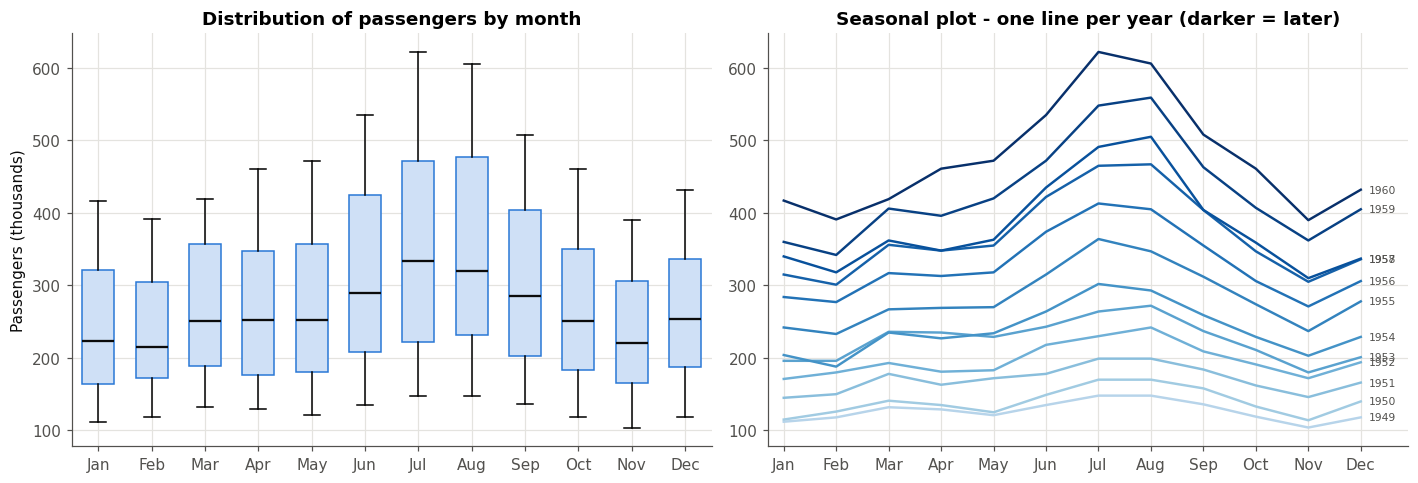

[saved] outputs/figures/06_seasonal_boxplot_and_plot.png


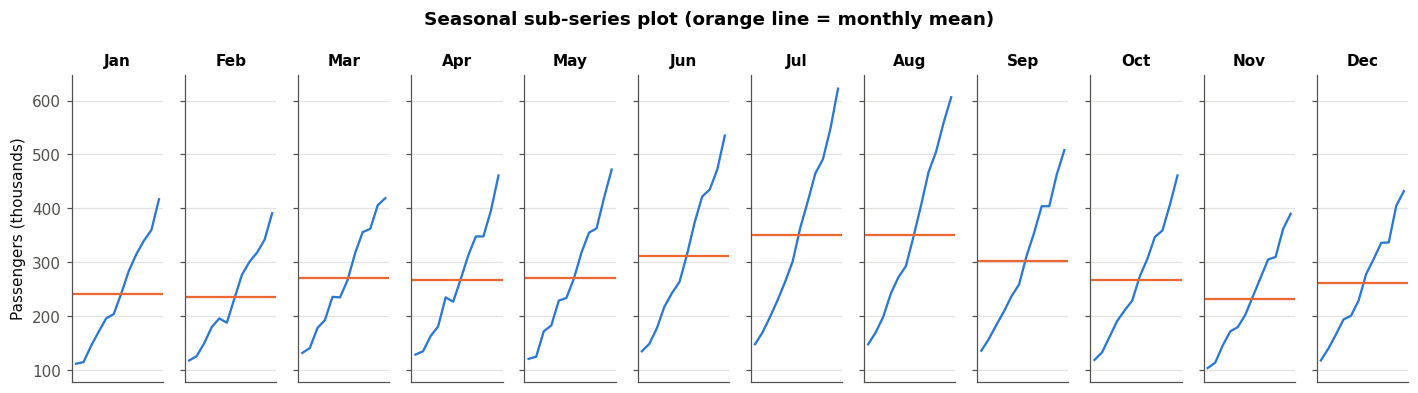

[saved] outputs/figures/07_seasonal_subseries.png


In [8]:
tmp = pd.DataFrame({"y": y, "year": y.index.year, "month": y.index.month})
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
data_by_month = [tmp.loc[tmp.month == m, "y"].values for m in range(1, 13)]
bp = axes[0].boxplot(data_by_month, tick_labels=months, patch_artist=True, widths=0.6,
                     medianprops=dict(color=INK, lw=1.5))
for patch in bp["boxes"]:
    patch.set_facecolor("#cfe0f6"); patch.set_edgecolor(C[0])
axes[0].set_title("Distribution of passengers by month")
axes[0].set_ylabel("Passengers (thousands)")

cmap = plt.get_cmap("Blues")
years = sorted(tmp.year.unique())
for i, yr in enumerate(years):
    s = tmp[tmp.year == yr]
    axes[1].plot(s.month, s.y, color=cmap(0.3 + 0.7 * i / (len(years) - 1)), lw=1.6)
    axes[1].text(12.15, s.y.iloc[-1], str(yr), fontsize=7, color=INK2, va="center")
axes[1].set_xticks(range(1, 13), months)
axes[1].set_xlim(0.7, 12.9)
axes[1].set_title("Seasonal plot - one line per year (darker = later)")
save(fig, "06_seasonal_boxplot_and_plot")

fig, axes = plt.subplots(1, 12, figsize=(13, 3.6), sharey=True)
for m, ax in enumerate(axes, start=1):
    s = tmp[tmp.month == m]
    ax.plot(s.year, s.y, color=C[0], lw=1.5)
    ax.axhline(s.y.mean(), color=C[1], lw=1.5)
    ax.set_title(months[m - 1], fontsize=10)
    ax.set_xticks([])
axes[0].set_ylabel("Passengers (thousands)")
fig.suptitle("Seasonal sub-series plot (orange line = monthly mean)", fontweight="bold")
save(fig, "07_seasonal_subseries")

July and August are the peak months, November is the lowest; every month grows
year after year (trend) while keeping the same relative position (stable seasonality).

## Step 3 - Stationarity tests (ADF and KPSS)

* **ADF (Augmented Dickey-Fuller):** $H_0$: the series has a unit root (non-stationary).
  p < 0.05 -> reject $H_0$ -> stationary.
* **KPSS:** $H_0$: the series is (level) stationary. p < 0.05 -> reject $H_0$ -> non-stationary.

Using both gives a stronger conclusion: *stationary* when ADF rejects **and**
KPSS does not reject.

In [9]:
def stationarity(series, name):
    s = series.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    adf_ok, kpss_ok = adf_p < 0.05, kpss_p >= 0.05
    verdict = ("Stationary" if adf_ok and kpss_ok else
               "Non-stationary" if not adf_ok and not kpss_ok else
               "Inconclusive (ADF %s, KPSS %s)" % ("stat." if adf_ok else "non-stat.",
                                                   "stat." if kpss_ok else "non-stat."))
    return {"Series": name, "n": len(s), "ADF stat": adf_stat, "ADF p-value": adf_p,
            "KPSS stat": kpss_stat, "KPSS p-value": kpss_p, "Conclusion": verdict}


log_y = np.log(y)
d1 = log_y.diff()
d12 = log_y.diff(12)
d1_12 = log_y.diff().diff(12)
tests = pd.DataFrame([
    stationarity(y, "Original Y"),
    stationarity(log_y, "log(Y)"),
    stationarity(d1, "log(Y), 1st difference"),
    stationarity(d12, "log(Y), seasonal difference (12)"),
    stationarity(d1_12, "log(Y), 1st + seasonal difference"),
])
tests.to_csv(OUT / "stationarity_tests.csv", index=False)
print(tests.round(4).to_string(index=False))
print("\n(KPSS p-values are truncated to the range 0.01-0.10 by the look-up table.)")

                           Series   n  ADF stat  ADF p-value  KPSS stat  KPSS p-value                               Conclusion
                       Original Y 144     0.815    9.919e-01      1.651          0.01                           Non-stationary
                           log(Y) 144    -1.717    4.224e-01      1.669          0.01                           Non-stationary
           log(Y), 1st difference 143    -2.717    7.110e-02      0.038          0.10 Inconclusive (ADF non-stat., KPSS stat.)
 log(Y), seasonal difference (12) 132    -2.710    7.240e-02      0.292          0.10 Inconclusive (ADF non-stat., KPSS stat.)
log(Y), 1st + seasonal difference 131    -4.443    2.000e-04      0.073          0.10                               Stationary

(KPSS p-values are truncated to the range 0.01-0.10 by the look-up table.)


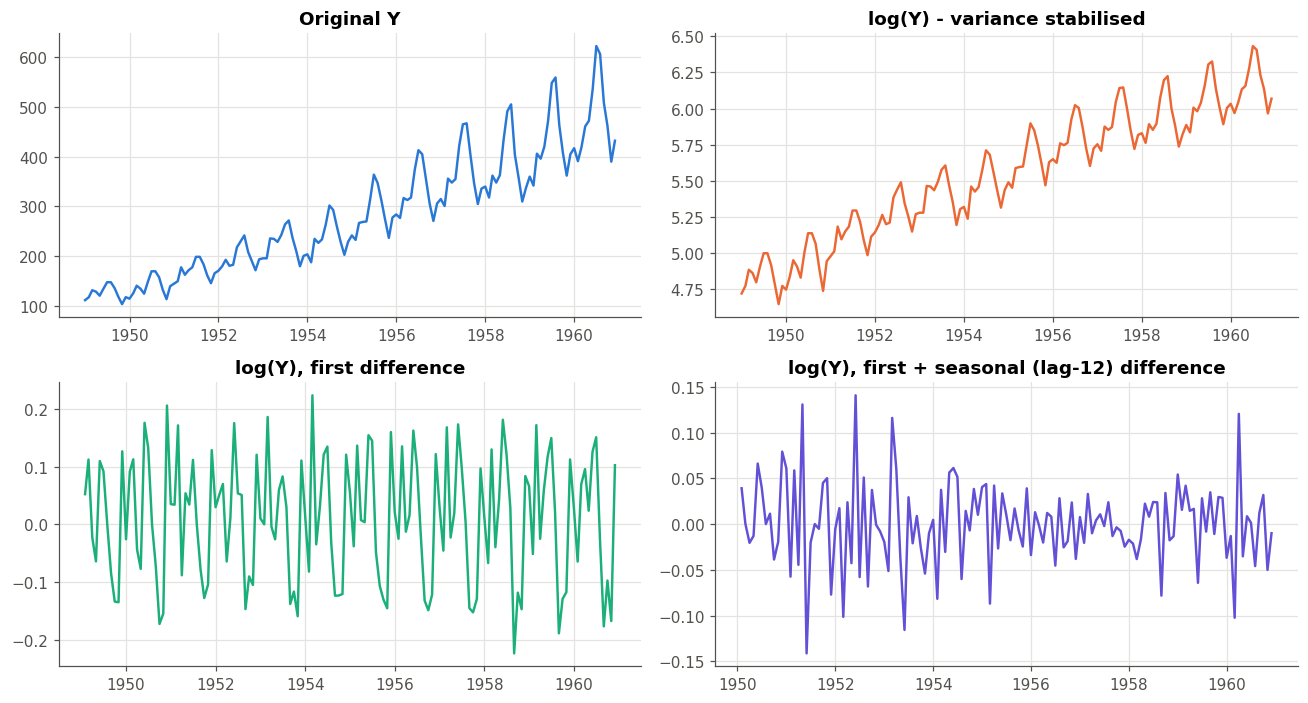

[saved] outputs/figures/08_transformations.png


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, (s, t, c) in zip(axes.ravel(), [
        (y, "Original Y", C[0]), (log_y, "log(Y) - variance stabilised", C[1]),
        (d1, "log(Y), first difference", C[2]),
        (d1_12, "log(Y), first + seasonal (lag-12) difference", C[6])]):
    ax.plot(s, color=c, lw=1.6)
    ax.set_title(t)
save(fig, "08_transformations")

**Interpretation.** The original series and log series are clearly non-stationary
(trend). The log transform stabilises the variance (seasonal swings become
equal in size). One regular difference removes the trend but the strong
seasonal pattern remains; the combination of **one regular + one seasonal
difference** of log(Y) passes both tests -> **d = 1, D = 1, s = 12**.

## Step 4 - ACF / PACF and model order identification

* **ACF** (autocorrelation function) - correlation of the series with its own lags.
  A sharp cut-off after lag *q* suggests an MA(q) term.
* **PACF** (partial ACF) - correlation at lag *k* after removing the effect of
  shorter lags. A cut-off after lag *p* suggests an AR(p) term.
* Spikes at lags 12, 24, ... identify the seasonal orders P and Q.

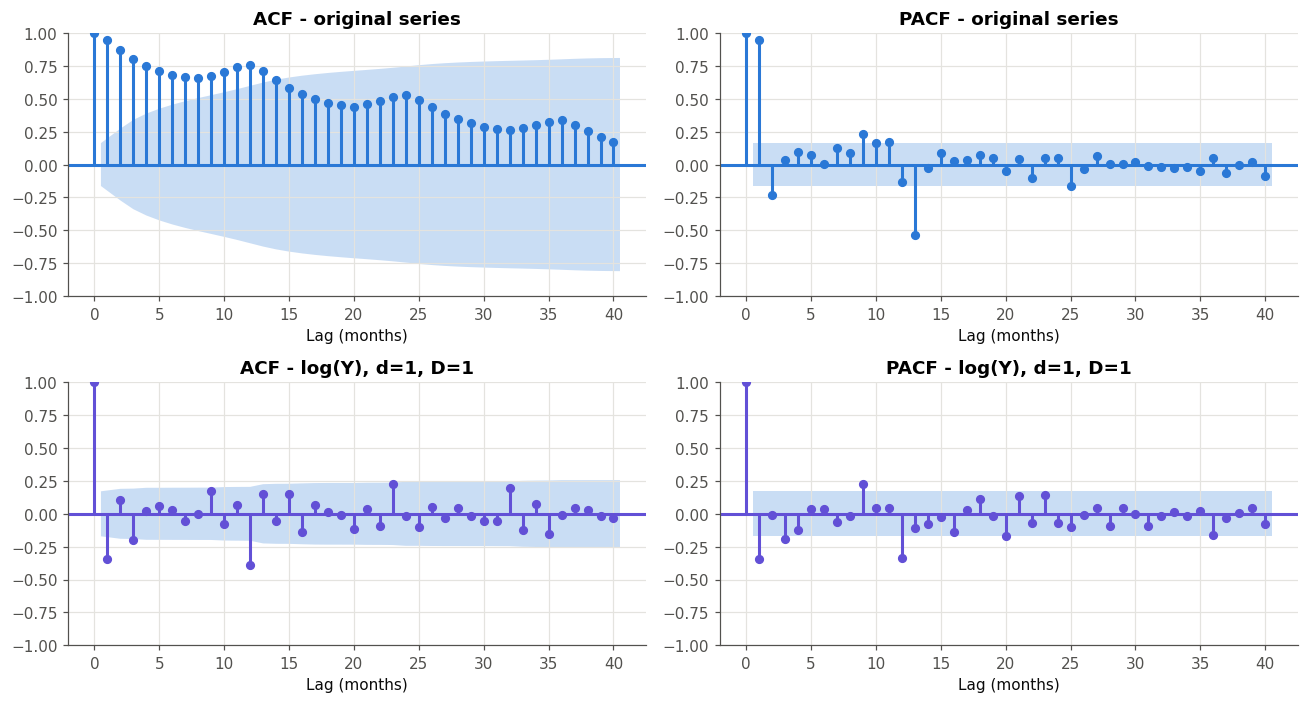

[saved] outputs/figures/09_acf_pacf.png
95% significance bound = +/-0.171
Significant ACF lags : [1, 3, 9, 12, 23, 32]
Significant PACF lags: [1, 3, 9, 12]


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
plot_acf(y, lags=40, ax=axes[0, 0], color=C[0], vlines_kwargs={"colors": C[0]})
axes[0, 0].set_title("ACF - original series")
plot_pacf(y, lags=40, ax=axes[0, 1], method="ywm", color=C[0], vlines_kwargs={"colors": C[0]})
axes[0, 1].set_title("PACF - original series")
plot_acf(d1_12.dropna(), lags=40, ax=axes[1, 0], color=C[6], vlines_kwargs={"colors": C[6]})
axes[1, 0].set_title("ACF - log(Y), d=1, D=1")
plot_pacf(d1_12.dropna(), lags=40, ax=axes[1, 1], method="ywm", color=C[6],
          vlines_kwargs={"colors": C[6]})
axes[1, 1].set_title("PACF - log(Y), d=1, D=1")
for ax in axes.ravel():
    ax.set_xlabel("Lag (months)")
save(fig, "09_acf_pacf")

from statsmodels.tsa.stattools import acf as _acf, pacf as _pacf
w = d1_12.dropna()
bound = 1.96 / np.sqrt(len(w))
acf_v, pacf_v = _acf(w, nlags=36), _pacf(w, nlags=36, method="ywm")
print("95%% significance bound = +/-%.3f" % bound)
print("Significant ACF lags :", [k for k in range(1, 37) if abs(acf_v[k]) > bound])
print("Significant PACF lags:", [k for k in range(1, 37) if abs(pacf_v[k]) > bound])

**Identification.** On the differenced log series the dominant ACF spikes are
negative ones at lag 1 (-0.34) and lag 12 (-0.39); the few others (lags 3, 9, 23)
barely cross the band. The PACF tails off at the start and around lag 12. This
points to a non-seasonal MA(1) and a seasonal MA(1):
**SARIMA(0,1,1)(0,1,1)[12]** - the famous Box-Jenkins *"airline model"*. We
confirm this with an AIC grid search below.

## Step 5 - Train/test split and model fitting

The last **24 months (1959-1960)** are held out as the test set; models are fit
on 1949-1958 (120 months) and forecast 24 months ahead.

| Model | Idea |
|---|---|
| Naive | next value = last observed value |
| Seasonal naive | next value = value in the same month last year |
| Moving average | forecast = mean of the last 12 months |
| Simple exponential smoothing (SES) | weighted average, weights decay geometrically (level only) |
| Holt-Winters (ETS) | level + trend + seasonal smoothing equations |
| ARIMA(p,1,q) | autoregressive + moving-average model on the differenced log series |
| SARIMA(p,1,q)(P,1,Q)[12] | ARIMA with additional seasonal AR/MA terms |

In [12]:
H = 24
train, test = y.iloc[:-H], y.iloc[-H:]
print("Train: %s to %s (%d obs)" % (train.index[0].strftime("%b %Y"), train.index[-1].strftime("%b %Y"), len(train)))
print("Test : %s to %s (%d obs)" % (test.index[0].strftime("%b %Y"), test.index[-1].strftime("%b %Y"), len(test)))

forecasts = {}
fitted_models = {}

# 1. Naive
forecasts["Naive"] = pd.Series(train.iloc[-1], index=test.index)
# 2. Seasonal naive: repeat the last observed year
forecasts["Seasonal naive"] = pd.Series(np.tile(train.iloc[-12:].values, H // 12), index=test.index)
# 3. Moving average (12-month window)
forecasts["Moving average (12)"] = pd.Series(train.iloc[-12:].mean(), index=test.index)
# 4. Simple exponential smoothing
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
forecasts["SES"] = ses.forecast(H)
print("SES alpha = %.3f" % ses.params["smoothing_level"])

Train: Jan 1949 to Dec 1958 (120 obs)
Test : Jan 1959 to Dec 1960 (24 obs)
SES alpha = 1.000


In [13]:
# 5. Holt-Winters: try additive / multiplicative seasonality, damped or not; pick lowest AIC
hw_results = []
for trend, seasonal, damped in itertools.product(["add"], ["add", "mul"], [False, True]):
    m = ExponentialSmoothing(train, trend=trend, seasonal=seasonal, seasonal_periods=12,
                             damped_trend=damped, initialization_method="estimated").fit()
    hw_results.append({"trend": trend, "seasonal": seasonal, "damped": damped, "AIC": m.aic, "model": m})
hw_table = pd.DataFrame(hw_results).drop(columns="model").sort_values("AIC")
print(hw_table.round(2).to_string(index=False))
best_hw = min(hw_results, key=lambda r: r["AIC"])
hw = best_hw["model"]
hw_label = "Holt-Winters (%s trend, %s season)" % (
    "damped" if best_hw["damped"] else "add.", "mul." if best_hw["seasonal"] == "mul" else "add.")
forecasts[hw_label] = hw.forecast(H)
fitted_models["Holt-Winters"] = hw
print("\nSelected:", hw_label)
print("alpha=%.3f beta=%.3f gamma=%.3f" % (hw.params["smoothing_level"], hw.params["smoothing_trend"],
                                         hw.params["smoothing_seasonal"]))

trend seasonal  damped    AIC
  add      mul   False 571.58
  add      mul    True 578.05
  add      add   False 619.39
  add      add    True 625.18

Selected: Holt-Winters (add. trend, mul. season)
alpha=0.364 beta=0.000 gamma=0.636


In [14]:
# 6. ARIMA(p,1,q) on log(Y): AIC grid search, p,q in 0..3
def fit_sarimax(series, order, sorder=(0, 0, 0, 0)):
    return SARIMAX(series, order=order, seasonal_order=sorder).fit(disp=False)


log_train = np.log(train)
arima_grid = []
for p, q in itertools.product(range(4), range(4)):
    try:
        res = fit_sarimax(log_train, (p, 1, q))
        arima_grid.append({"order": (p, 1, q), "AIC": res.aic, "BIC": res.bic})
    except Exception:
        pass
arima_grid = pd.DataFrame(arima_grid).sort_values("AIC")
print("Top 5 ARIMA models by AIC:")
print(arima_grid.head().round(2).to_string(index=False))
arima_order = arima_grid.iloc[0]["order"]
arima = fit_sarimax(log_train, arima_order)
forecasts["ARIMA%s" % (arima_order,)] = np.exp(arima.get_forecast(H).predicted_mean)
fitted_models["ARIMA"] = arima

Top 5 ARIMA models by AIC:
    order     AIC     BIC
(3, 1, 3) -226.63 -207.18
(2, 1, 1) -208.37 -197.25
(3, 1, 2) -207.70 -191.02
(3, 1, 1) -206.98 -193.09
(1, 1, 2) -206.86 -195.74


In [15]:
# 7. SARIMA(p,1,q)(P,1,Q)[12] on log(Y): AIC grid search, p,q in 0..2, P,Q in 0..1
sarima_grid = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        res = fit_sarimax(log_train, (p, 1, q), (P, 1, Q, 12))
        sarima_grid.append({"order": (p, 1, q), "seasonal_order": (P, 1, Q, 12),
                            "AIC": res.aic, "BIC": res.bic})
    except Exception:
        pass
sarima_grid = pd.DataFrame(sarima_grid).sort_values("AIC").reset_index(drop=True)
sarima_grid.to_csv(OUT / "sarima_grid_search.csv", index=False)
print("Models tried:", len(sarima_grid))
print("Top 8 SARIMA models by AIC:")
print(sarima_grid.head(8).round(2).to_string(index=False))
s_order, s_sorder = sarima_grid.iloc[0]["order"], sarima_grid.iloc[0]["seasonal_order"]
sarima = fit_sarimax(log_train, s_order, s_sorder)
sarima_label = "SARIMA%s%s" % (s_order, s_sorder[:3]) + "[12]"
forecasts[sarima_label] = np.exp(sarima.get_forecast(H).predicted_mean)
fitted_models["SARIMA"] = sarima
print()
print(sarima.summary().tables[1])

Models tried: 36
Top 8 SARIMA models by AIC:
    order seasonal_order     AIC     BIC
(0, 1, 1)  (0, 1, 1, 12) -389.01 -380.99
(1, 1, 0)  (0, 1, 1, 12) -388.64 -380.62
(1, 1, 1)  (0, 1, 1, 12) -387.28 -376.59
(0, 1, 1)  (1, 1, 1, 12) -387.22 -376.53
(0, 1, 2)  (0, 1, 1, 12) -387.07 -376.37
(1, 1, 0)  (1, 1, 1, 12) -386.77 -376.08
(2, 1, 0)  (0, 1, 1, 12) -386.66 -375.97
(2, 1, 1)  (0, 1, 1, 12) -386.61 -373.25



                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3423      0.087     -3.921      0.000      -0.513      -0.171
ma.S.L12      -0.5406      0.105     -5.158      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.866      0.000       0.001       0.002


## Step 6 - Evaluation: MAE, RMSE, MAPE

* $MAE = \frac{1}{n}\sum |y_t - \hat y_t|$ - average absolute error (same unit as data)
* $RMSE = \sqrt{\frac{1}{n}\sum (y_t - \hat y_t)^2}$ - penalises large errors more
* $MAPE = \frac{100}{n}\sum \left|\frac{y_t - \hat y_t}{y_t}\right|$ - error in percent, scale-free

In [16]:
def metrics(actual, pred):
    e = actual - pred
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(e / actual))}


metric_table = pd.DataFrame({k: metrics(test, v) for k, v in forecasts.items()}).T
metric_table = metric_table.sort_values("RMSE")
metric_table.index.name = "Model"
metric_table.round(3).to_csv(OUT / "metrics.csv")
print(metric_table.round(2))
best_name = metric_table.index[0]
print("\nBest model on the test set (lowest RMSE):", best_name)

                                           MAE    RMSE  MAPE (%)
Model                                                           
Holt-Winters (add. trend, mul. season)   28.98   32.49      6.39
SARIMA(0, 1, 1)(0, 1, 1)[12]             39.44   43.18      8.52
Seasonal naive                           71.25   76.99     15.52
ARIMA(3, 1, 3)                           70.70   92.44     14.09
Moving average (12)                      77.83  103.21     15.47
Naive                                   115.25  137.33     23.58
SES                                     115.25  137.33     23.58

Best model on the test set (lowest RMSE): Holt-Winters (add. trend, mul. season)


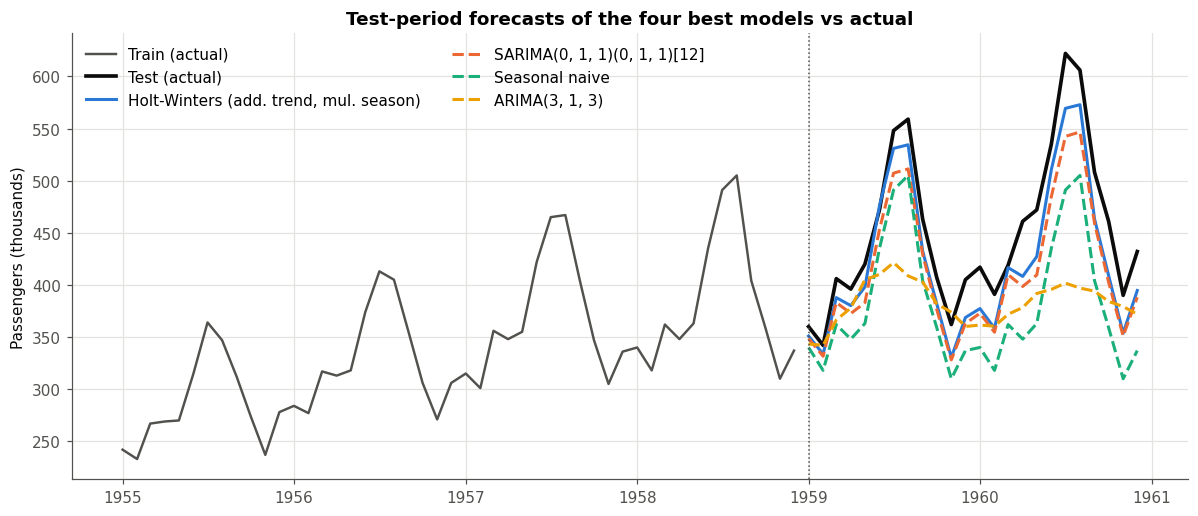

[saved] outputs/figures/10_forecasts_vs_actual.png


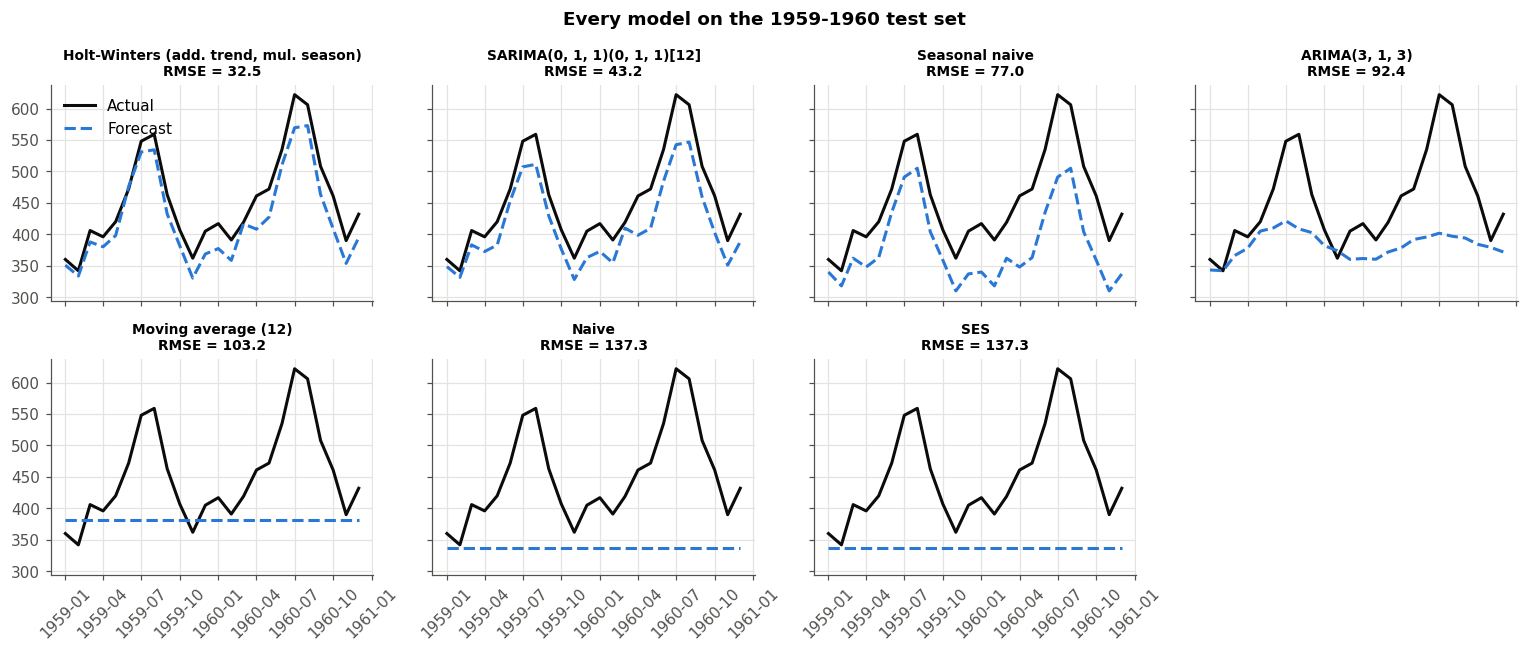

[saved] outputs/figures/11_all_models_test_period.png


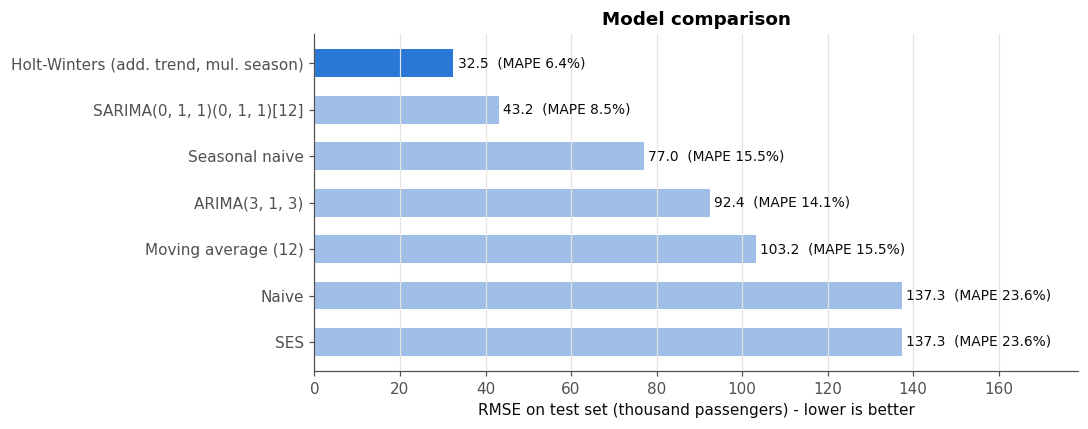

[saved] outputs/figures/12_model_comparison_rmse.png


In [17]:
order_plot = list(metric_table.index)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(train.loc["1955":], color=INK2, lw=1.6, label="Train (actual)")
ax.plot(test, color=INK, lw=2.4, label="Test (actual)")
top = order_plot[:4]
for i, name in enumerate(top):
    ax.plot(forecasts[name], color=C[i], lw=2, ls="--" if i else "-", label=name)
ax.axvline(test.index[0], color=INK2, lw=1, ls=":")
ax.set_title("Test-period forecasts of the four best models vs actual")
ax.set_ylabel("Passengers (thousands)")
ax.legend(loc="upper left", ncol=2)
save(fig, "10_forecasts_vs_actual")

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), order_plot):
    ax.plot(test, color=INK, lw=2, label="Actual")
    ax.plot(forecasts[name], color=C[0], lw=2, ls="--", label="Forecast")
    ax.set_title("%s\nRMSE = %.1f" % (name, metric_table.loc[name, "RMSE"]), fontsize=9)
    ax.tick_params(axis="x", rotation=45)
for ax in axes.ravel()[len(order_plot):]:
    ax.axis("off")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Every model on the 1959-1960 test set", fontweight="bold")
save(fig, "11_all_models_test_period")

fig, ax = plt.subplots(figsize=(10, 4))
mt = metric_table.iloc[::-1]
bars = ax.barh(mt.index, mt["RMSE"], color=[C[0] if n == best_name else "#9fbfe8" for n in mt.index],
               height=0.6)
for b, v, mp in zip(bars, mt["RMSE"], mt["MAPE (%)"]):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, "%.1f  (MAPE %.1f%%)" % (v, mp),
            va="center", fontsize=9, color=INK)
ax.set_xlabel("RMSE on test set (thousand passengers) - lower is better")
ax.set_title("Model comparison")
ax.set_xlim(0, mt["RMSE"].max() * 1.3)
ax.grid(axis="y", visible=False)
save(fig, "12_model_comparison_rmse")

## Step 7 - Residual diagnostics

A good model leaves residuals that look like **white noise**: mean zero, constant
variance, approximately normal, and no autocorrelation. We check this with a
residual plot, histogram, normal Q-Q plot, residual ACF and the
**Ljung-Box test** ($H_0$: residuals are independently distributed - p > 0.05 is good).
Diagnostics are shown for the best model on the test set and, for comparison,
for the SARIMA model chosen by Box-Jenkins identification.

=== Best model: Holt-Winters (add. trend, mul. season) ===


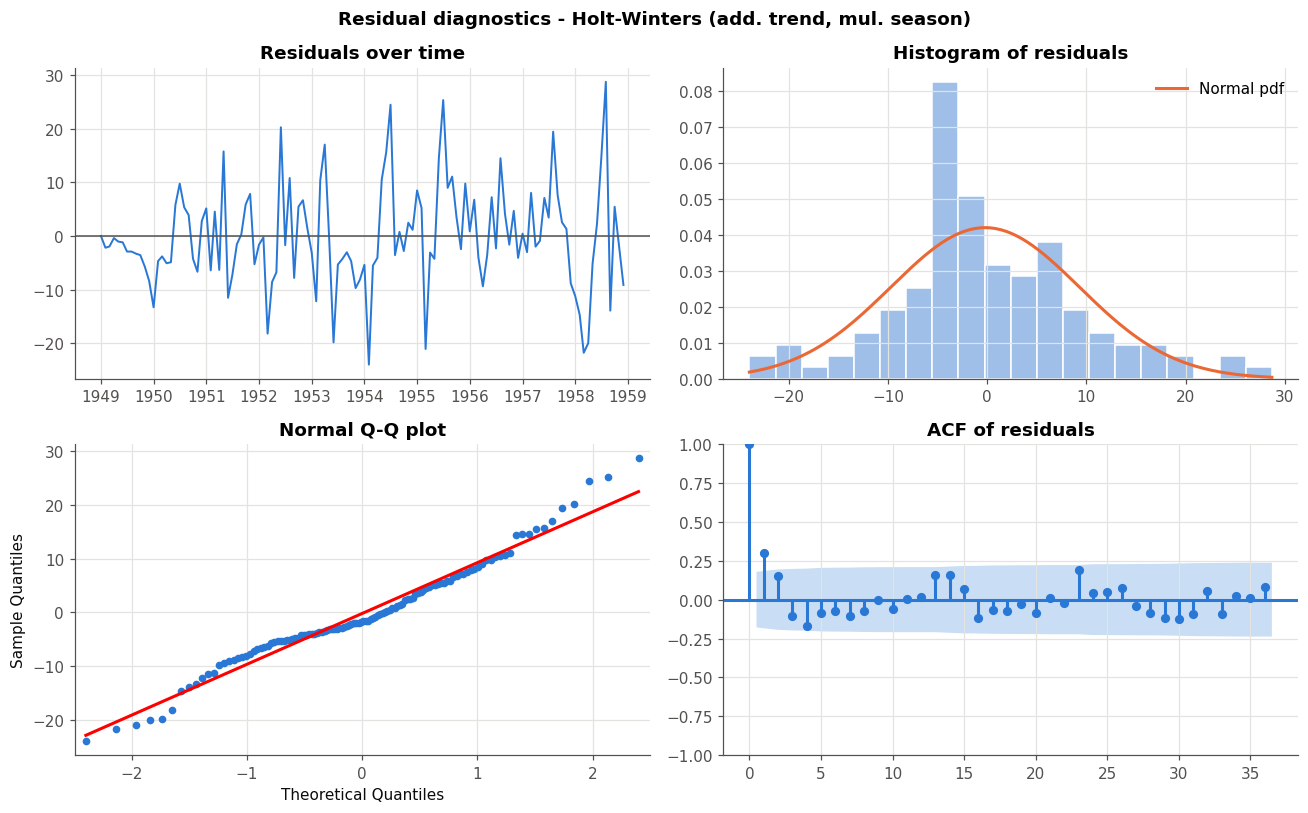

[saved] outputs/figures/13_residual_diagnostics_best_model.png
Residual mean = -0.2043, std = 9.5086
Ljung-Box test:
     lb_stat  lb_pvalue
lag                    
6     20.405      0.002
12    23.040      0.027
18    34.093      0.012
24    41.276      0.015
Jarque-Bera normality : stat = 5.176, p = 0.0752
Shapiro-Wilk normality: stat = 0.975, p = 0.0229

=== Box-Jenkins model: SARIMA(0, 1, 1)(0, 1, 1)[12] (log scale) ===


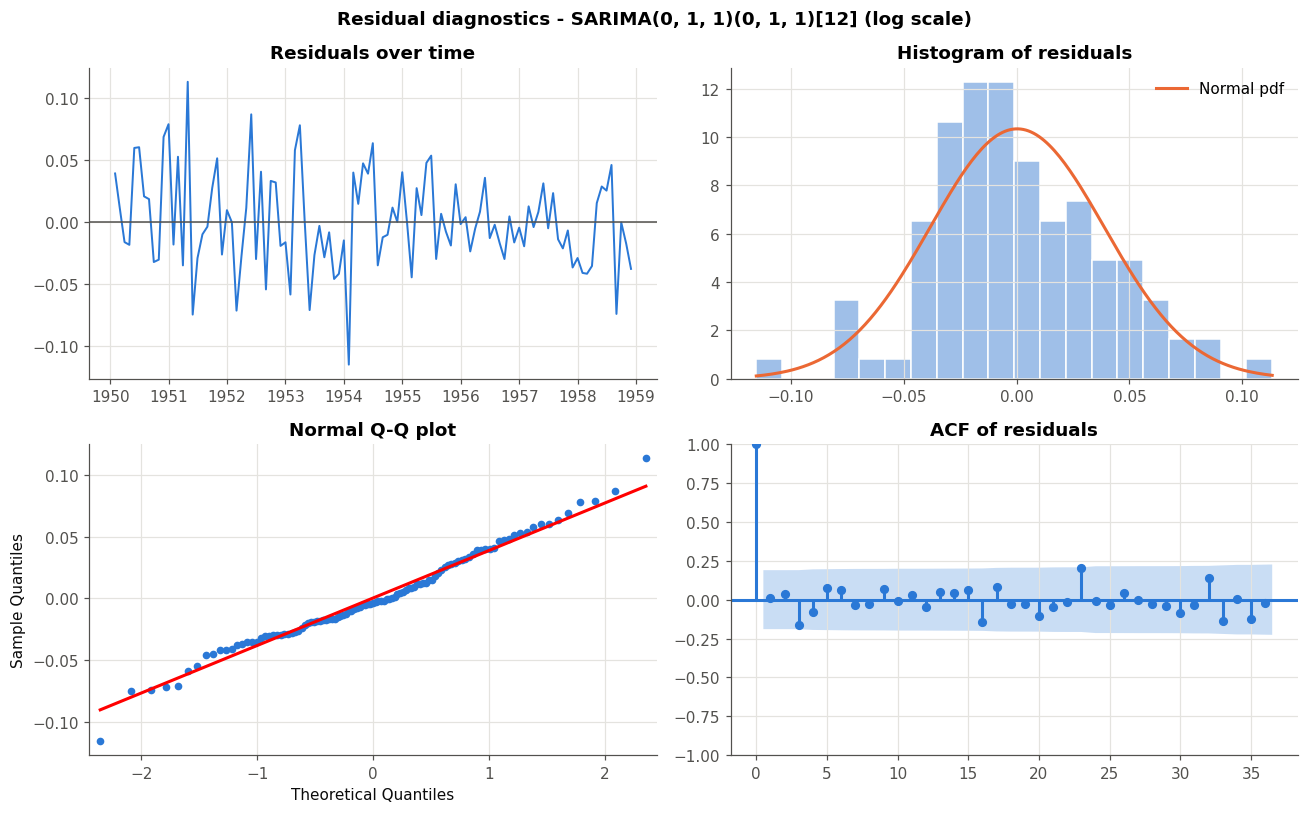

[saved] outputs/figures/14_residual_diagnostics_sarima.png
Residual mean = 0.0003, std = 0.0386
Ljung-Box test:
     lb_stat  lb_pvalue
lag                    
6      4.883      0.559
12     6.072      0.912
18    10.506      0.914
24    17.987      0.804
Jarque-Bera normality : stat = 1.095, p = 0.5784
Shapiro-Wilk normality: stat = 0.988, p = 0.4870


In [18]:
def residual_diagnostics(resid, title, name):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
    axes[0, 0].plot(resid, color=C[0], lw=1.3)
    axes[0, 0].axhline(0, color=INK2, lw=1)
    axes[0, 0].set_title("Residuals over time")
    axes[0, 1].hist(resid, bins=20, density=True, color="#9fbfe8", edgecolor="white")
    xs = np.linspace(resid.min(), resid.max(), 200)
    axes[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color=C[1], label="Normal pdf")
    axes[0, 1].set_title("Histogram of residuals")
    axes[0, 1].legend()
    qqplot(resid, line="s", ax=axes[1, 0], markerfacecolor=C[0], markeredgecolor=C[0], markersize=4)
    axes[1, 0].set_title("Normal Q-Q plot")
    plot_acf(resid, lags=36, ax=axes[1, 1], color=C[0], vlines_kwargs={"colors": C[0]})
    axes[1, 1].set_title("ACF of residuals")
    fig.suptitle("Residual diagnostics - %s" % title, fontweight="bold")
    save(fig, name)

    lb = acorr_ljungbox(resid, lags=[6, 12, 18, 24], return_df=True)
    lb.index.name = "lag"
    jb_stat, jb_p = stats.jarque_bera(resid)
    sw_stat, sw_p = stats.shapiro(resid)
    print("Residual mean = %.4f, std = %.4f" % (resid.mean(), resid.std()))
    print("Ljung-Box test:")
    print(lb.round(4))
    print("Jarque-Bera normality : stat = %.3f, p = %.4f" % (jb_stat, jb_p))
    print("Shapiro-Wilk normality: stat = %.3f, p = %.4f" % (sw_stat, sw_p))
    return lb


def model_resid(label):
    if label.startswith("SARIMA"):
        return fitted_models["SARIMA"].resid.iloc[13:]     # drop burn-in from differencing (log scale)
    if label.startswith("Holt"):
        return fitted_models["Holt-Winters"].resid          # original scale
    return fitted_models["ARIMA"].resid.iloc[1:]


print("=== Best model:", best_name, "===")
lb_best = residual_diagnostics(model_resid(best_name), best_name, "13_residual_diagnostics_best_model")
lb_best.round(4).to_csv(OUT / "ljung_box_best_model.csv")
if not best_name.startswith("SARIMA"):
    print()
    print("=== Box-Jenkins model:", sarima_label, "(log scale) ===")
    lb_sarima = residual_diagnostics(model_resid(sarima_label), sarima_label + " (log scale)",
                                     "14_residual_diagnostics_sarima")
    lb_sarima.round(4).to_csv(OUT / "ljung_box_sarima.csv")
else:
    lb_sarima = lb_best

## Step 8 - Refit on the full data and forecast the next 24 months

The selected model is re-estimated on all 144 observations (1949-1960) and
used to forecast January 1961 - December 1962 with 80% and 95% prediction
intervals. For SARIMA the intervals come from the model on the log scale
(back-transformed with $e^x$); for Holt-Winters they come from 5,000 simulated
future paths with multiplicative errors (2.5/10/90/97.5 percentiles).

In [19]:
F = 24
if best_name.startswith("SARIMA"):
    final = fit_sarimax(np.log(y), s_order, s_sorder)
    fc = final.get_forecast(F)
    ci95, ci80 = np.exp(fc.conf_int(alpha=0.05)), np.exp(fc.conf_int(alpha=0.20))
    point = np.exp(fc.predicted_mean)
else:                                      # Holt-Winters: simulation-based intervals
    final = ExponentialSmoothing(y, trend="add", seasonal=best_hw["seasonal"], seasonal_periods=12,
                                 damped_trend=best_hw["damped"], initialization_method="estimated").fit()
    point = final.forecast(F)
    sims = final.simulate(F, repetitions=5000, error="mul", random_state=42)
    ci95 = pd.DataFrame({0: sims.quantile(0.025, axis=1), 1: sims.quantile(0.975, axis=1)})
    ci80 = pd.DataFrame({0: sims.quantile(0.10, axis=1), 1: sims.quantile(0.90, axis=1)})

future = pd.DataFrame({"Forecast": point.values,
                       "Lower 80%": ci80.iloc[:, 0].values, "Upper 80%": ci80.iloc[:, 1].values,
                       "Lower 95%": ci95.iloc[:, 0].values, "Upper 95%": ci95.iloc[:, 1].values},
                      index=point.index)
future.index.name = "Month"
future.round(1).to_csv(OUT / "forecast_next_24_months.csv")
print(future.round(1).to_string())
print("\nForecast total 1961: %.0f thousand (1960 actual: %.0f, growth %.1f%%)" % (
    future.loc["1961", "Forecast"].sum(), y.loc["1960"].sum(),
    100 * (future.loc["1961", "Forecast"].sum() / y.loc["1960"].sum() - 1)))
print("Forecast total 1962: %.0f thousand" % future.loc["1962", "Forecast"].sum())

            Forecast  Lower 80%  Upper 80%  Lower 95%  Upper 95%
Month                                                           
1961-01-01     445.2      422.0      468.5      409.2      480.9
1961-02-01     418.2      394.8      441.5      383.4      454.1
1961-03-01     465.3      439.1      492.5      425.4      507.6
1961-04-01     495.0      465.7      525.2      450.6      540.7
1961-05-01     505.5      474.3      536.6      458.4      552.6
1961-06-01     573.3      536.9      610.4      518.4      630.1
1961-07-01     663.6      618.9      708.6      597.4      732.1
1961-08-01     654.9      611.0      698.5      590.1      722.8
1961-09-01     546.8      509.4      585.0      489.4      606.0
1961-10-01     488.4      454.0      523.3      435.7      541.5
1961-11-01     415.7      385.9      447.5      370.6      463.6
1961-12-01     460.4      426.2      494.3      408.8      515.4
1962-01-01     474.1      433.1      517.4      412.6      541.5
1962-02-01     445.2     

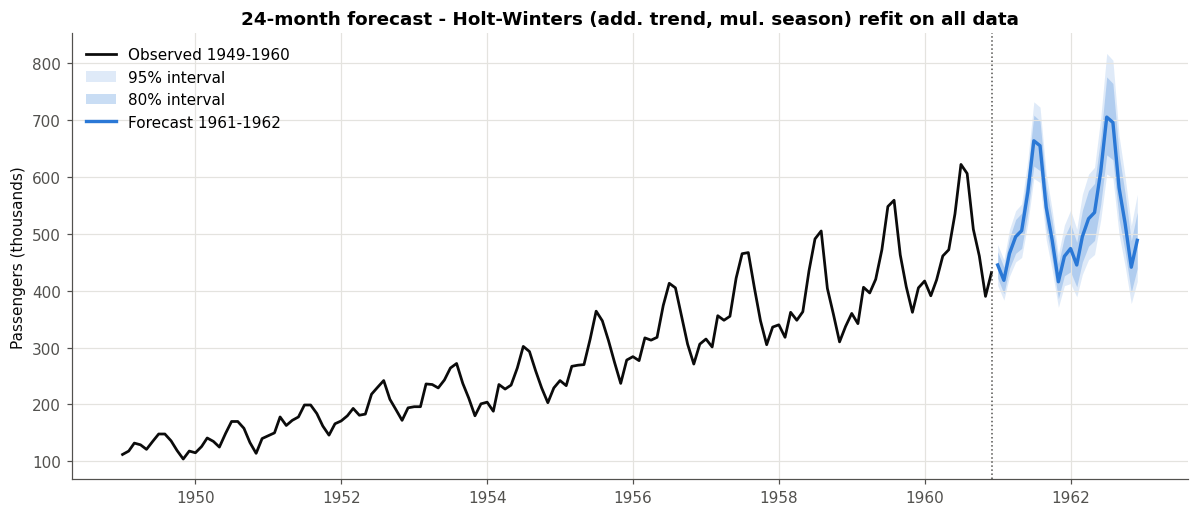

[saved] outputs/figures/15_future_forecast.png


In [20]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(y, color=INK, lw=1.8, label="Observed 1949-1960")
ax.fill_between(future.index, future["Lower 95%"], future["Upper 95%"], color=C[0], alpha=0.15,
                lw=0, label="95% interval")
ax.fill_between(future.index, future["Lower 80%"], future["Upper 80%"], color=C[0], alpha=0.25,
                lw=0, label="80% interval")
ax.plot(future["Forecast"], color=C[0], lw=2.2, label="Forecast 1961-1962")
ax.axvline(y.index[-1], color=INK2, lw=1, ls=":")
ax.set_title("24-month forecast - %s refit on all data" % best_name)
ax.set_ylabel("Passengers (thousands)")
ax.legend(loc="upper left")
save(fig, "15_future_forecast")

## Step 9 - Conclusions

In [21]:
b = metric_table.loc[best_name]
sn = metric_table.loc["Seasonal naive"]
print("1. The series has a strong upward trend and multiplicative 12-month seasonality "
      "(peak Jul/Aug, trough Nov); STL strength of trend = %.2f, seasonality = %.2f." % (F_t, F_s))
print("2. Original series is non-stationary (ADF p = %.3f, KPSS p = %.3f); log + 1st + seasonal "
      "differencing makes it stationary (ADF p = %.4f, KPSS p = %.3f)." % (
          tests.iloc[0]["ADF p-value"], tests.iloc[0]["KPSS p-value"],
          tests.iloc[4]["ADF p-value"], tests.iloc[4]["KPSS p-value"]))
print("3. ACF/PACF and the AIC grid search select %s." % sarima_label)
print("4. Best model on the 24-month test set: %s - MAE %.2f, RMSE %.2f, MAPE %.2f%% "
      "(seasonal naive baseline: RMSE %.2f, MAPE %.2f%%)." % (
          best_name, b["MAE"], b["RMSE"], b["MAPE (%)"], sn["RMSE"], sn["MAPE (%)"]))
for i, (lab, lbt) in enumerate([(best_name, lb_best), (sarima_label, lb_sarima)]):
    ok = bool((lbt["lb_pvalue"] > 0.05).all())
    print("%s %s residuals: Ljung-Box p-values (lags 6-24) %s -> %s." % (
        "5." if i == 0 else "  ", lab, "all > 0.05" if ok else "min %.3f" % lbt["lb_pvalue"].min(),
        "white noise (model adequate)" if ok else "some autocorrelation left"))
    if best_name.startswith("SARIMA"):
        break
print("6. Forecast: about %.0f thousand passengers in 1961 and %.0f thousand in 1962, "
      "peaking at %.0f thousand in %s." % (
          future.loc["1961", "Forecast"].sum(), future.loc["1962", "Forecast"].sum(),
          future["Forecast"].max(), future["Forecast"].idxmax().strftime("%b %Y")))

1. The series has a strong upward trend and multiplicative 12-month seasonality (peak Jul/Aug, trough Nov); STL strength of trend = 1.00, seasonality = 0.96.
2. Original series is non-stationary (ADF p = 0.992, KPSS p = 0.010); log + 1st + seasonal differencing makes it stationary (ADF p = 0.0002, KPSS p = 0.100).
3. ACF/PACF and the AIC grid search select SARIMA(0, 1, 1)(0, 1, 1)[12].
4. Best model on the 24-month test set: Holt-Winters (add. trend, mul. season) - MAE 28.98, RMSE 32.49, MAPE 6.39% (seasonal naive baseline: RMSE 76.99, MAPE 15.52%).
5. Holt-Winters (add. trend, mul. season) residuals: Ljung-Box p-values (lags 6-24) min 0.002 -> some autocorrelation left.
   SARIMA(0, 1, 1)(0, 1, 1)[12] residuals: Ljung-Box p-values (lags 6-24) all > 0.05 -> white noise (model adequate).
6. Forecast: about 6132 thousand passengers in 1961 and 6518 thousand in 1962, peaking at 705 thousand in Jul 1962.
